In [1]:
import pandas as pd
import numpy as np


train = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv')
test = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv')



/tmp/ipykernel_16/1152002669.py:5: DtypeWarning: Columns (38,39) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv')


In [2]:
print(train.shape)
print(test.shape)

(138701, 50)
(15000, 49)


In [3]:
train.head()

,TransactionID,TargetValue,AssetID,ProductConfigID,DataOriginCode,VendorPartnerID,ManufactureYear,OperationalHoursMeter,UtilizationTier,TransactionDate,...,col20,col21,col22,col23,col24,col25,col27,col28,col29,col30
0,1139309,57000.0,117665,88,ACH138,GTX,1997,4640.0,Low,2005-03-26,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Standard,Conventional
1,1139316,26500.0,1001282,4616,ACH138,GTX,2005,508.0,Low,2009-12-18,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1139317,21000.0,772709,1948,ACH138,GTX,1994,11540.0,High,2005-08-26,...,Steel,None or Unspecified,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN
3,1139322,27000.0,902010,3550,ACH138,GTX,2002,4883.0,High,2006-11-17,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1139333,21500.0,1036259,36014,ACH138,GTX,2009,302.0,Low,2010-08-27,...,Rubber,None or Unspecified,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN


In [4]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138701 entries, 0 to 138700
Data columns (total 50 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   TransactionID              138701 non-null  int64  
 1   TargetValue                138701 non-null  float64
 2   AssetID                    138701 non-null  int64  
 3   ProductConfigID            138701 non-null  int64  
 4   DataOriginCode             138701 non-null  object 
 5   VendorPartnerID            138701 non-null  object 
 6   ManufactureYear            138701 non-null  int64  
 7   OperationalHoursMeter      82058 non-null   float64
 8   UtilizationTier            50475 non-null   object 
 9   TransactionDate            138701 non-null  object 
 10  Spec_FullDescriptor        138701 non-null  object 
 11  Spec_BaseClass             138701 non-null  object 
 12  Spec_SubClass              101716 non-null  object 
 13  Spec_ReleaseSeries         32

In [5]:
train.describe()

,TransactionID,TargetValue,AssetID,ProductConfigID,ManufactureYear,OperationalHoursMeter
count,1.387010e+05,138701.000000,1.387010e+05,138701.000000,138701.000000,8.205800e+04
mean,2.186276e+06,41521.874047,1.204814e+06,7286.421922,1891.640853,4.553719e+03
std,1.128497e+06,26361.125948,5.287376e+05,7542.421537,306.992001,2.792204e+04
min,1.139309e+06,7500.000000,8.000000e+00,39.000000,1001.000000,0.000000e+00
25%,1.465754e+06,20500.000000,1.007930e+06,1693.000000,1990.000000,0.000000e+00
50%,1.751884e+06,35000.000000,1.246956e+06,3852.000000,1998.000000,1.620000e+03
75%,2.372139e+06,57000.000000,1.495817e+06,11873.000000,2004.000000,5.001000e+03
max,6.333410e+06,142000.000000,2.478476e+06,37209.000000,2015.000000,1.729600e+06


In [6]:
train.isnull().sum()

TransactionID                     0
TargetValue                       0
AssetID                           0
ProductConfigID                   0
DataOriginCode                    0
VendorPartnerID                   0
ManufactureYear                   0
OperationalHoursMeter         56643
UtilizationTier               88226
TransactionDate                   0
Spec_FullDescriptor               0
Spec_BaseClass                    0
Spec_SubClass                 36985
Spec_ReleaseSeries           105805
Spec_VariantModifier          86369
AssetScaleFactor              41210
FunctionalClassification          0
RegionCode                        0
InventoryGroupCategory            0
InventoryGroupDescription         0
col1                         104915
CabinType                         0
Forks                        109382
col3                         109448
col4                         128320
DrivetrainType                89956
col5                         128320
col6                        

In [7]:
train.duplicated().sum()

np.int64(0)

In [8]:
numerical_cols = train.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = train.select_dtypes(include=['object', 'category']).columns

print("Numerical:", numerical_cols)
print("Categorical:", categorical_cols)

Numerical: Index(['TransactionID', 'TargetValue', 'AssetID', 'ProductConfigID',
       'ManufactureYear', 'OperationalHoursMeter'],
      dtype='object')
Categorical: Index(['DataOriginCode', 'VendorPartnerID', 'UtilizationTier',
       'TransactionDate', 'Spec_FullDescriptor', 'Spec_BaseClass',
       'Spec_SubClass', 'Spec_ReleaseSeries', 'Spec_VariantModifier',
       'AssetScaleFactor', 'FunctionalClassification', 'RegionCode',
       'InventoryGroupCategory', 'InventoryGroupDescription', 'col1',
       'CabinType', 'Forks', 'col3', 'col4', 'DrivetrainType', 'col5', 'col6',
       'col7', 'col8', 'col9', 'col10', 'col11', 'col12', 'col13', 'col14',
       'col15', 'col16', 'col18', 'col19', 'col20', 'col21', 'col22', 'col23',
       'col24', 'col25', 'col27', 'col28', 'col29', 'col30'],
      dtype='object')


In [9]:
train['TargetValue'].value_counts()

TargetValue
25000.0    2426
35000.0    2350
30000.0    2256
40000.0    2188
26000.0    2158
           ... 
80300.0       1
62100.0       1
41600.0       1
25600.0       1
56250.0       1
Name: count, Length: 675, dtype: int64

In [10]:
train['TargetValue'].describe()

count    138701.000000
mean      41521.874047
std       26361.125948
min        7500.000000
25%       20500.000000
50%       35000.000000
75%       57000.000000
max      142000.000000
Name: TargetValue, dtype: float64

In [11]:
missing = train.isnull().sum()

missing_percent = (missing / len(train)) * 100

missing_df = pd.DataFrame({
    "Missing Values": missing,
    "Percentage": missing_percent
})

missing_df.sort_values(by="Percentage", ascending=False)

,Missing Values,Percentage
col19,138635,99.952416
col18,138635,99.952416
col5,128320,92.515555
col4,128320,92.515555
col27,123742,89.214930
col28,123742,89.214930
col29,119829,86.393753
col30,119829,86.393753
col13,115296,83.125572
col14,115296,83.125572


In [12]:
train.describe()

,TransactionID,TargetValue,AssetID,ProductConfigID,ManufactureYear,OperationalHoursMeter
count,1.387010e+05,138701.000000,1.387010e+05,138701.000000,138701.000000,8.205800e+04
mean,2.186276e+06,41521.874047,1.204814e+06,7286.421922,1891.640853,4.553719e+03
std,1.128497e+06,26361.125948,5.287376e+05,7542.421537,306.992001,2.792204e+04
min,1.139309e+06,7500.000000,8.000000e+00,39.000000,1001.000000,0.000000e+00
25%,1.465754e+06,20500.000000,1.007930e+06,1693.000000,1990.000000,0.000000e+00
50%,1.751884e+06,35000.000000,1.246956e+06,3852.000000,1998.000000,1.620000e+03
75%,2.372139e+06,57000.000000,1.495817e+06,11873.000000,2004.000000,5.001000e+03
max,6.333410e+06,142000.000000,2.478476e+06,37209.000000,2015.000000,1.729600e+06


In [13]:
train["TargetValue"].describe()

count    138701.000000
mean      41521.874047
std       26361.125948
min        7500.000000
25%       20500.000000
50%       35000.000000
75%       57000.000000
max      142000.000000
Name: TargetValue, dtype: float64

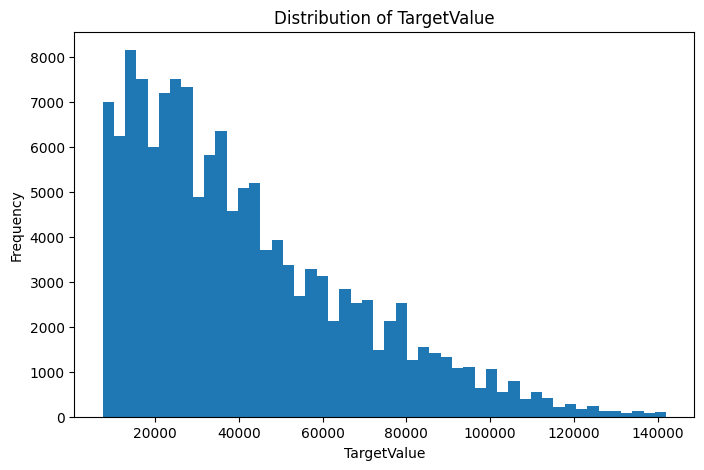

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(train["TargetValue"], bins=50)
plt.title("Distribution of TargetValue")
plt.xlabel("TargetValue")
plt.ylabel("Frequency")
plt.show()

In [15]:
train.duplicated().sum()

np.int64(0)

In [16]:
train.select_dtypes(include=['int64','float64']).corr()

,TransactionID,TargetValue,AssetID,ProductConfigID,ManufactureYear,OperationalHoursMeter
TransactionID,1.000000,-0.012093,0.373844,0.129477,0.065617,0.008129
TargetValue,-0.012093,1.000000,-0.238719,0.057265,0.204439,0.001994
AssetID,0.373844,-0.238719,1.000000,0.154943,-0.029941,0.003505
ProductConfigID,0.129477,0.057265,0.154943,1.000000,-0.009438,-0.013551
ManufactureYear,0.065617,0.204439,-0.029941,-0.009438,1.000000,-0.008256
OperationalHoursMeter,0.008129,0.001994,0.003505,-0.013551,-0.008256,1.000000


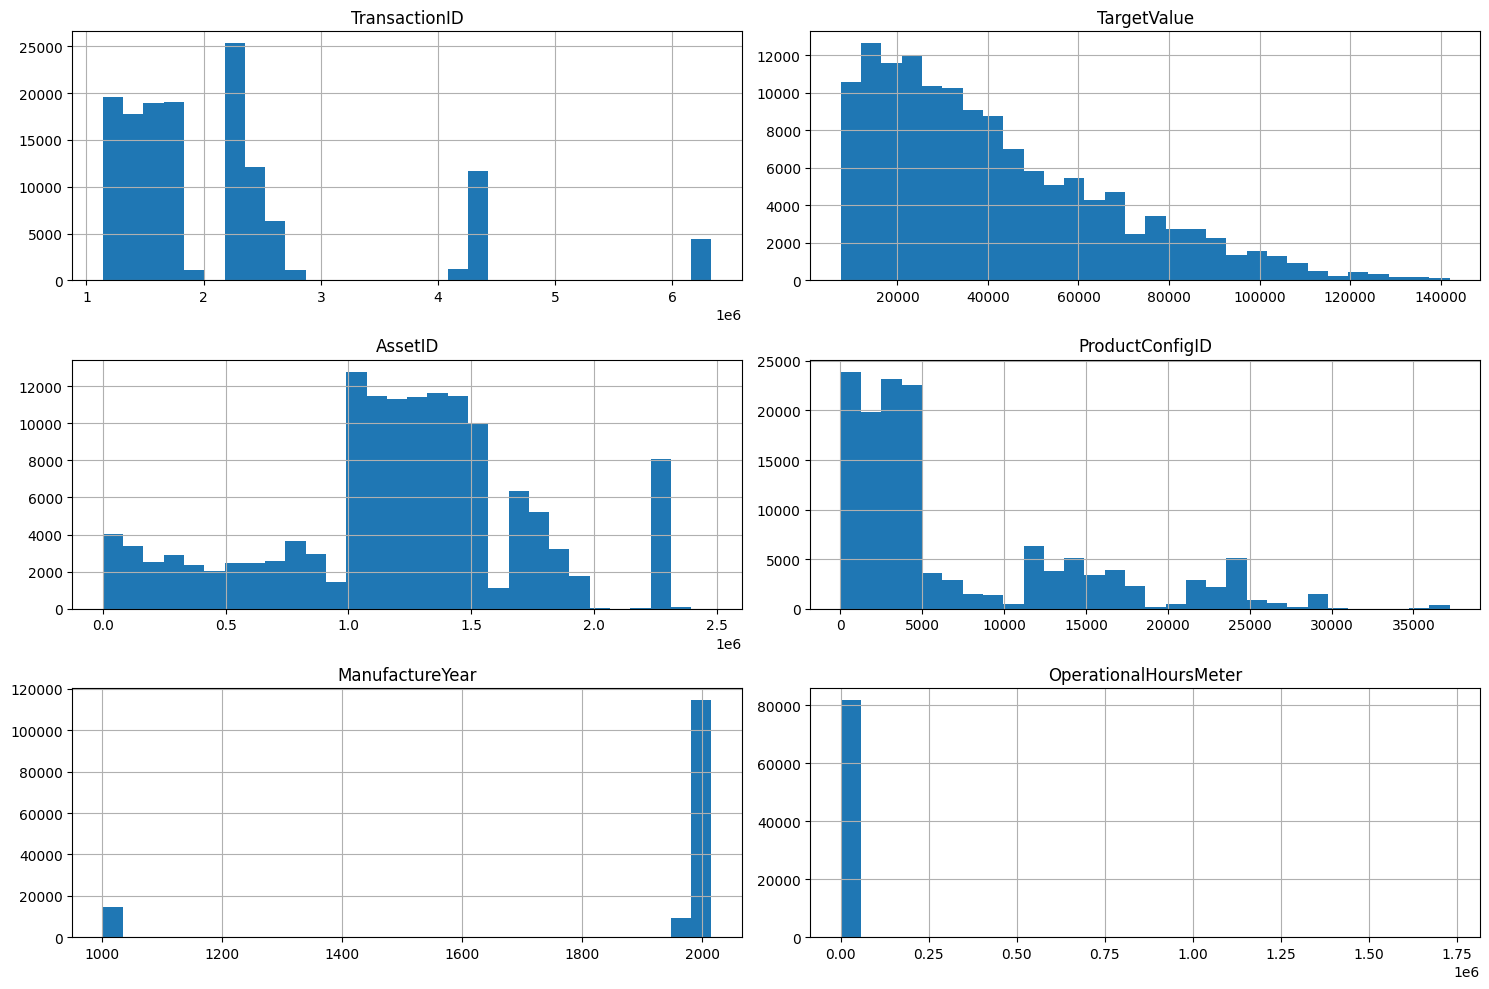

In [17]:
numeric_cols = train.select_dtypes(include=['int64','float64']).columns

train[numeric_cols].hist(figsize=(15,10), bins=30)
plt.tight_layout()
plt.show()